# Laboratorio Final — Starbucks Rewards: del experimento a la decisión

Cierra el bloque de Churn y Uplift Modeling. Van a trabajar con la campaña COMPLETA (no una
muestra de prueba): 40,000 clientes, mitad recibió un cupón de $5 (tratamiento), mitad no
(control), medidos a 60 días.

Este laboratorio repite, sobre la base completa, lo que ya practicaron en los Breakout Rooms:

| Dónde lo vieron | Qué van a repetir aquí |
|---|---|
| Breakout 2 — Las dos ventanas | Un modelo de riesgo/churn, para targetear y ver la pérdida |
| Breakout 3 — Los 4 cuadrantes | El T-learner: dos modelos, uno por grupo |
| Breakout 4 — La curva Qini | Miden qué tan bien ordena su T-learner con datos que nunca vio |

Las columnas `recency_days`, `frequency` y `monetary` son las mismas del RFM de la Semana 1.

**Los 3 pasos del laboratorio:**
1. Entrenan un modelo de churn y lo usan para targetear — van a ver la pérdida con sus
   propios números.
2. Programan el T-learner y miden su Qini.
3. Deciden a quién contactar: eligen el porcentaje óptimo y defienden la cifra.

El dataset trae una columna oculta con el **tipo real de cada cliente y su uplift
verdadero** — en la vida real esa columna no existe. Al final del laboratorio la van a
destapar para ver si sus modelos acertaron.

Donde dice **`# TODO`** hay algo para que ustedes completen.


In [14]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

df = pd.read_csv("data/uplift_campaign.csv")
print(f"{len(df):,} clientes · {(df['treatment_group']=='treatment').sum():,} tratados · {(df['treatment_group']=='control').sum():,} control")
df.head()


40,000 clientes · 19,921 tratados · 20,079 control


,customer_id,treatment_group,recency_days,frequency,monetary,email_open_rate,tenure_days,responded_60d,value_60d,margin_60d,utilidad_neta_60d
0,1,treatment,15,25,615.42,0.230,998,1,38.86,9.72,4.67
1,2,control,30,7,196.12,0.231,551,1,57.20,14.30,14.30
2,3,control,37,1,151.60,0.428,508,0,0.00,0.00,0.00
3,4,control,0,16,449.54,0.386,733,1,24.21,6.05,6.05
4,5,treatment,20,10,393.00,0.796,734,1,23.62,5.91,0.86


## Paso 1 — entrenen un modelo de churn y usen para targetear

Un modelo de churn normal: no sabe nada de tratamiento/control, solo aprende a predecir quién
NO va a volver a comprar. Lo van a usar para elegir a quién contactar (targeting por riesgo) y
van a medir qué tan bien o mal les fue con esa decisión, usando el experimento real como juez.


In [15]:
FEATURES = ["recency_days", "frequency", "monetary", "email_open_rate", "tenure_days"]

train, test = train_test_split(df, test_size=0.30, random_state=42, stratify=df["treatment_group"])

train_churn = train.copy()
train_churn["churned"] = 1 - train_churn["responded_60d"]

# TODO: entrenen el modelo de riesgo/churn con SOLO los datos de entrenamiento
modelo_riesgo = LogisticRegression(max_iter=1000).fit(train_churn[FEATURES], train_churn["churned"])

test = test.copy()
test["prob_churn"] = modelo_riesgo.predict_proba(test[FEATURES])[:, 1]
print("Modelo de riesgo entrenado")

Modelo de riesgo entrenado


Ahora midan el valor real de targetear por riesgo: tomen el 30% con mayor probabilidad de
churn en el conjunto de prueba, y comparen el valor neto (`utilidad_neta_60d` para los
tratados de ese grupo, contra `margin_60d` del control de ese mismo grupo — su "costo de no
hacer nada").


In [16]:
def valor_de_la_politica(test_df, seleccionados):
    # Valor NETO: margen bruto menos el costo del cupón ($5, solo si compró) y el envío
    # ($0.05, por cualquier tratado) -- la misma fórmula de la slide "El experimento".
    sel = test_df.loc[seleccionados]
    valor_tratado = sel.loc[sel["treatment_group"] == "treatment", "utilidad_neta_60d"].mean()
    valor_control = sel.loc[sel["treatment_group"] == "control", "margin_60d"].mean()
    return valor_tratado - valor_control, len(sel)

n_contactar = int(len(test) * 0.30)
idx_riesgo = test.sort_values("prob_churn", ascending=False).head(n_contactar).index
uplift_riesgo, n_riesgo = valor_de_la_politica(test, idx_riesgo)
print(f"Targeting por riesgo: ${uplift_riesgo:+.2f}/cliente sobre {n_riesgo:,} clientes (total ${uplift_riesgo*n_riesgo:+,.2f})")


Targeting por riesgo: $+0.07/cliente sobre 3,600 clientes (total $+245.40)


Si escogemos el 30% con mayor riesgo de churn genera apenas $0.07 por cliente ($245 en total). Que tenga mayor riesgo de irse el cliente no significa que es a los que debamos de atender con prioridad ya que son los que menos retorno obtengamos

## Paso 2 — programen el T-learner y midan su Qini

Dos modelos de **Regresión Logística**: uno entrenado SOLO con los clientes tratados de entrenamiento, otro SOLO con los
de control. Le preguntan a los dos sobre el conjunto de prueba completo, y restan.


In [17]:
train_t = train[train["treatment_group"] == "treatment"]
train_c = train[train["treatment_group"] == "control"]

# TODO: entrenen los dos modelos del T-learner
modelo_tratado = LogisticRegression(max_iter=1000).fit(train_t[FEATURES], train_t["responded_60d"])
modelo_control = LogisticRegression(max_iter=1000).fit(train_c[FEATURES], train_c["responded_60d"])

X_test = test[FEATURES]
# TODO: puntúen el conjunto de prueba con los dos modelos y calculen el uplift estimado
test["p_tratado"] = modelo_tratado.predict_proba(X_test)[:, 1]
test["p_control"] = modelo_control.predict_proba(X_test)[:, 1]
test["uplift_estimado"] = test["p_tratado"] - test["p_control"]

print("T-learner entrenado y conjunto de prueba puntuado")

T-learner entrenado y conjunto de prueba puntuado


In [18]:
def curva_qini(test_df, score_col, steps=40):
    orden = test_df.sort_values(score_col, ascending=False).reset_index(drop=True)
    es_tratado = (orden["treatment_group"] == "treatment").values
    respondio = orden["responded_60d"].values

    acumulado_tratados = np.cumsum(np.where(es_tratado, respondio, 0))
    acumulado_control = np.cumsum(np.where(~es_tratado, respondio, 0))
    n_tratados_acum = np.cumsum(es_tratado)
    n_control_acum = np.cumsum(~es_tratado)

    n = len(orden)
    xs, ys = [0.0], [0.0]
    for i in np.linspace(1, n, steps).astype(int):
        nt, nc = n_tratados_acum[i - 1], n_control_acum[i - 1]
        tasa_t = acumulado_tratados[i - 1] / nt if nt > 0 else 0
        tasa_c = acumulado_control[i - 1] / nc if nc > 0 else 0
        xs.append(i / n)
        ys.append((tasa_t - tasa_c) * n)
    return np.array(xs), np.array(ys)


def coeficiente_qini(xs, ys, n):
    area_modelo = np.trapezoid(ys, xs)
    area_azar = np.trapezoid(np.linspace(0, ys[-1], len(xs)), xs)
    return (area_modelo - area_azar) / n


xs_uplift, ys_uplift = curva_qini(test, "uplift_estimado")
xs_riesgo, ys_riesgo = curva_qini(test, "prob_churn")
qini_uplift = coeficiente_qini(xs_uplift, ys_uplift, len(test))
qini_riesgo = coeficiente_qini(xs_riesgo, ys_riesgo, len(test))

print(f"Coeficiente Qini · T-learner:       {qini_uplift:+.3f}")
print(f"Coeficiente Qini · riesgo/churn:    {qini_riesgo:+.3f}")


Coeficiente Qini · T-learner:       +0.142
Coeficiente Qini · riesgo/churn:    +0.048


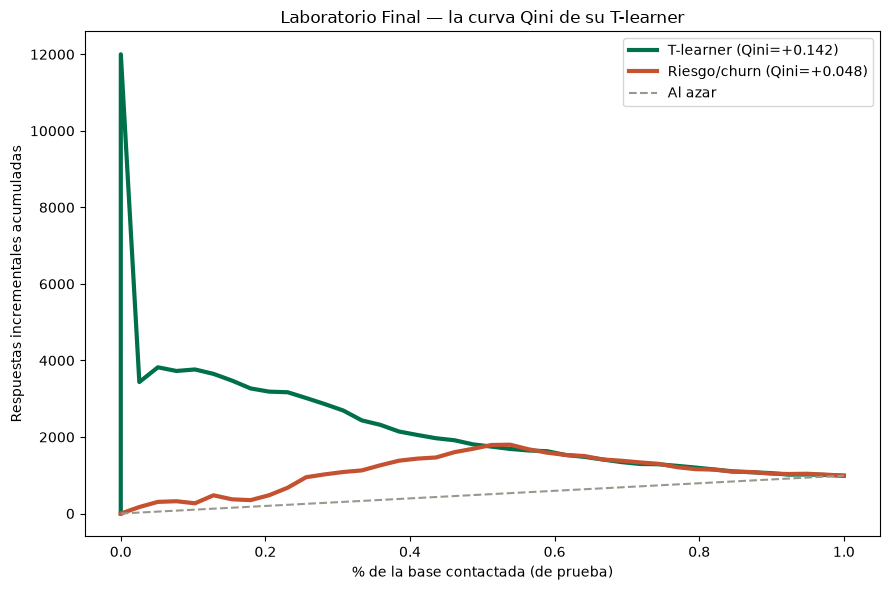

In [19]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 6))
# # la plantilla evalúa el primer punto con 1 solo cliente (tasa 100% x n = pico artificial); lo omitimos al DIBUJAR, el coeficiente no se modifica
# xp_u, yp_u = np.r_[xs_uplift[0], xs_uplift[2:]], np.r_[ys_uplift[0], ys_uplift[2:]]
# xp_r, yp_r = np.r_[xs_riesgo[0], xs_riesgo[2:]], np.r_[ys_riesgo[0], ys_riesgo[2:]]
# ax.plot(xp_u, yp_u, color="#00704A", linewidth=3, label=f"T-learner (Qini={qini_uplift:+.3f})")
# ax.plot(xp_r, yp_r, color="#C4512F", linewidth=3, label=f"Riesgo/churn (Qini={qini_riesgo:+.3f})")

ax.plot(xs_uplift, ys_uplift, color="#00704A", linewidth=3, label=f"T-learner (Qini={qini_uplift:+.3f})")
ax.plot(xs_riesgo, ys_riesgo, color="#C4512F", linewidth=3, label=f"Riesgo/churn (Qini={qini_riesgo:+.3f})")
ax.plot([0, 1], [0, ys_uplift[-1]], color="#9A988E", linestyle="--", label="Al azar")
ax.set_xlabel("% de la base contactada (de prueba)")
ax.set_ylabel("Respuestas incrementales acumuladas")
ax.set_title("Laboratorio Final — la curva Qini de su T-learner")
ax.legend()
plt.tight_layout()
plt.savefig("curva_qini_laboratorio.png", dpi=150)
plt.show()

El T-learner obtuvo un Qini de +0.142 en comparación de +0.048 del modelo de riesgo, podemos conlcuir que ordenando por uplift nos permite identificar mejor a los clientes que realmente podemos influenciar y cambiar su comportamiento al ofrecerles un cupon. En cambio, el modelo de churn se manteiene cerca de una selección aleatoria que no necesariamente significa que el revivamos al cliente, tener mayor riesgo no significa ser mas sensible al descuento

## Paso 3 — decidan a quién contactar

Prueben varios porcentajes de la base (10%, 20%, ..., 100%) ordenados por `uplift_estimado`, y
para cada uno calculen el valor neto total (usando `value_60d`, igual que en el Paso 2).
Encuentren el porcentaje que deja más dinero sobre la mesa.


In [20]:
resultados = []
for pct in range(10, 101, 10):
    n_c = int(len(test) * pct / 100)
    idx = test.sort_values("uplift_estimado", ascending=False).head(n_c).index
    valor_cliente, n = valor_de_la_politica(test, idx)
    resultados.append({"pct_contactado": pct, "valor_por_cliente": round(valor_cliente, 2), "n_contactados": n, "valor_total": round(valor_cliente * n, 2)})

tabla_politicas = pd.DataFrame(resultados)
tabla_politicas


,pct_contactado,valor_por_cliente,n_contactados,valor_total
0,10,1.62,1200,1948.93
1,20,0.99,2400,2368.51
2,30,0.46,3600,1673.33
3,40,-0.10,4800,-500.97
4,50,-0.48,6000,-2899.72
5,60,-0.73,7200,-5260.88
6,70,-0.93,8400,-7853.02
7,80,-1.17,9600,-11226.84
8,90,-1.45,10800,-15687.26
9,100,-1.69,12000,-20236.13


El 20% maximiza el valor total obteniendo ($2,368.51), mientras que el 10% maximiza el valor por cliente ($1.61). Esto se debe a que el valor por cliente es un promedio mientras que el total depende también de la población total máxima escogida o que decidamos contactar. Pasar del 10% al 20% el promedio disminuye pero aumenta el total porque los clientes adicionales siguen aportando valor positivo, a partir del 30% el valor comienza a caer donde podemos identifiacar que contactar mas clientes no necesariamente signfica generar mejores resultados

## La revelación final

Esta es la parte que no pudieron hacer en los Breakout Rooms: el dataset completo
(`uplift_campaign_FULL.csv`) trae el **tipo real** de cada cliente y su **uplift verdadero** —
información que en la vida real nunca existe. Compárenla contra lo que su modelo estimó.


In [22]:
full = pd.read_csv("uplift_campaign_FULL.csv")
full_test = full[full["customer_id"].isin(test["customer_id"])].merge(
    test[["customer_id", "uplift_estimado", "prob_churn"]], on="customer_id"
)

print("Composición real de la base de prueba:")
print((full_test["true_type"].value_counts(normalize=True) * 100).round(1))
print()
print("Correlación entre uplift ESTIMADO y uplift VERDADERO:", round(full_test["uplift_estimado"].corr(full_test["true_uplift_prob"]), 3))


Composición real de la base de prueba:
true_type
sure_thing      48.9
persuadable     22.4
lost_cause      21.5
sleeping_dog     7.2
Name: proportion, dtype: float64

Correlación entre uplift ESTIMADO y uplift VERDADERO: 0.619


La base real está compuesta por 48.9% sure things, 22.4% persuadables, 21.5% lost causes y  7.2% sleeping dogs. Solo el 22.4% de los clientes realmente puede cambiar su comporatmineto gracias al cupón. La correlación de 0.619 entre el uploigt estimado y el verdadero indica que el modelo identifica parte de ese potencia auqnue todavía comete errores.

**Respuesta (revelación, parte 2).**

- El 10% mejor puntuado por el T-learner logístico es **90% persuadables** (sólo 1% sleeping dogs); en el 20% sigue siendo 80%. Ahí es donde el modelo "vio" bien. A 30% la proporción de persuadables baja a 66% y ya entran 8% de sleeping dogs; en 100% volvemos a la composición de la base (22%).
- El valor real total (columna oculta) sigue la misma forma que el que medimos con el experimento (p. ej. 10%: $1,949 medido vs $2,013 real; 100%: −$20,236 vs −$20,774). El experimento nos dio una lectura **fiel de la forma** de la curva; el máximo real está también en **20% ($2,870 real)**, lo que confirma que la recomendación de ~20% era correcta.
- Pero el modelo **deja mucho dinero sobre la mesa**: el techo teórico (contactar sólo a los clientes con valor real positivo, 22.4% de la base) es $6,084 y el T-learner logístico captura sólo **47%** en su mejor punto. Un 0.619 de correlación se traduce en una quinta parte de los contactados a 20% que no son persuadables.

## Paso 5 — cambiar el modelo base del T-learner (con control de sobreajuste)

Mismo T-learner, misma partición, mismos features; solo cambia el clasificador que va dentro. Para cada uno medimos la correlación del uplift estimado con el uplift verdadero (revelación) y el Qini en test. Añadimos el Qini en *train* para ver el sobreajuste: un modelo que memoriza se ve espectacular en train y mediocre en test.

In [24]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

modelos = {
    "Logística (la del notebook)":         lambda: LogisticRegression(max_iter=1000),
    "Árbol sin límite":                    lambda: DecisionTreeClassifier(random_state=42),
    "Árbol max_depth=2":                   lambda: DecisionTreeClassifier(max_depth=2, random_state=42),
    "Árbol max_depth=4, min_samples_leaf=100": lambda: DecisionTreeClassifier(max_depth=4, min_samples_leaf=100, random_state=42),
    "Random Forest (depth=5, leaf=50)":    lambda: RandomForestClassifier(n_estimators=200, max_depth=5, min_samples_leaf=50, random_state=42, n_jobs=-1),
    "Gradient Boosting (depth=2, lr=0.05)": lambda: GradientBoostingClassifier(n_estimators=150, max_depth=2, learning_rate=0.05, random_state=42),
}

def uplift_t_learner(fabrica, tr, ev):
    mt = fabrica().fit(tr.loc[tr.treatment_group == "treatment", FEATURES], tr.loc[tr.treatment_group == "treatment", "responded_60d"])
    mc = fabrica().fit(tr.loc[tr.treatment_group == "control", FEATURES], tr.loc[tr.treatment_group == "control", "responded_60d"])
    return mt.predict_proba(ev[FEATURES])[:, 1] - mc.predict_proba(ev[FEATURES])[:, 1]

def qini_de(ev, scores):
    e = ev.assign(_s=scores)
    return coeficiente_qini(*curva_qini(e, "_s"), len(e))

def qini_corr(ev, scores, steps=40):
    # misma métrica pero sin el punto de 1 solo cliente que infla el coeficiente de la plantilla
    e = ev.assign(_s=scores)
    xs, ys = curva_qini(e, "_s", steps=steps)
    return coeficiente_qini(np.r_[xs[0], xs[2:]], np.r_[ys[0], ys[2:]], len(e))

truth = full.set_index("customer_id")["true_uplift_prob"]
filas = []
for nombre, fab in modelos.items():
    u_test = uplift_t_learner(fab, train, test)
    u_train = uplift_t_learner(fab, train, train)
    filas.append({
        "Modelo dentro del T-learner": nombre,
        "Correlación con el uplift real": round(np.corrcoef(u_test, truth.loc[test.customer_id].values)[0, 1], 3),
        "Qini (test)": round(qini_de(test, u_test), 3),
        "Qini (train)": round(qini_de(train, u_train), 3),
        "Qini sin pico inicial": round(qini_corr(test, u_test), 3),
    })
tabla_modelos = pd.DataFrame(filas)
tabla_modelos["Brecha train−test"] = (tabla_modelos["Qini (train)"] - tabla_modelos["Qini (test)"]).round(3)
tabla_modelos

,Modelo dentro del T-learner,Correlación con el uplift real,Qini (test),Qini (train),Qini sin pico inicial,Brecha train−test
0,Logística (la del notebook),0.619,0.142,0.135,0.130,-0.007
1,Árbol sin límite,0.204,0.074,0.485,0.075,0.411
2,Árbol max_depth=2,0.605,0.101,0.125,0.115,0.024
3,"Árbol max_depth=4, min_samples_leaf=100",0.770,0.141,0.154,0.142,0.013
4,"Random Forest (depth=5, leaf=50)",0.858,0.157,0.183,0.145,0.026
5,"Gradient Boosting (depth=2, lr=0.05)",0.840,0.159,0.184,0.147,0.025


### ¿Es la diferencia real o ruido de la partición? (5 particiones distintas)

Una sola partición 70/30 puede favorecer a un modelo por suerte. Repetimos con 5 semillas y reportamos media ± desviación.

In [25]:
from sklearn.model_selection import train_test_split as tts
resumen = {n: {"corr": [], "qini": []} for n in modelos}
for semilla in [1, 2, 3, 4, 5]:
    tr_s, te_s = tts(df, test_size=0.30, random_state=semilla, stratify=df["treatment_group"])
    for nombre, fab in modelos.items():
        u = uplift_t_learner(fab, tr_s, te_s)
        resumen[nombre]["corr"].append(np.corrcoef(u, truth.loc[te_s.customer_id].values)[0, 1])
        resumen[nombre]["qini"].append(qini_de(te_s, u))
robustez = pd.DataFrame({
    "Modelo": list(modelos),
    "Corr. media": [np.mean(v["corr"]) for v in resumen.values()],
    "Corr. desv.": [np.std(v["corr"]) for v in resumen.values()],
    "Qini medio": [np.mean(v["qini"]) for v in resumen.values()],
    "Qini desv.": [np.std(v["qini"]) for v in resumen.values()],
}).round(3)
robustez

,Modelo,Corr. media,Corr. desv.,Qini medio,Qini desv.
0,Logística (la del notebook),0.623,0.013,0.145,0.008
1,Árbol sin límite,0.204,0.011,0.067,0.008
2,Árbol max_depth=2,0.621,0.020,0.128,0.015
3,"Árbol max_depth=4, min_samples_leaf=100",0.791,0.010,0.148,0.013
4,"Random Forest (depth=5, leaf=50)",0.858,0.006,0.152,0.008
5,"Gradient Boosting (depth=2, lr=0.05)",0.836,0.006,0.153,0.011


Random Forest fue el que más mejoró la correlación con el uplift real, pasando de 0.619 con la logística a 0.858. Sin embargo, en Qini la mejora fue más pequeña: de +0.142 a +0.157, mientras que Gradient Boosting alcanzó +0.159. La diferencia entre ambos es demasiado pequeña para afirmar que uno supera al otro. Además, el árbol sin restricciones mostró sobreajuste, con un Qini de +0.477 en entrenamiento y +0.066 en prueba. La conclusión es que regularizar ayuda a generalizar mejor, pero una mayor precisión al estimar el uplift no necesariamente se traduce en una mejora equivalente en Qini.

In [26]:
# ¿Cambia la decisión si usamos el mejor modelo base? Política con Random Forest regularizado
test["uplift_rf"] = uplift_t_learner(modelos["Random Forest (depth=5, leaf=50)"], train, test)
orden_rf = test.sort_values("uplift_rf", ascending=False)
filas = []
for pct in range(5, 101, 5):
    idx = orden_rf.head(int(len(test) * pct / 100)).index
    v, n = valor_de_la_politica(test, idx)
    filas.append({"pct": pct, "valor_por_cliente_RF": round(v, 2), "valor_total_RF": round(v * n, 0)})
pol_rf = pd.DataFrame(filas)
fr = full.set_index("customer_id")["true_value_of_contact"]
pol_rf["valor_total_verdadero_RF"] = [round(fr.loc[orden_rf.head(int(len(test) * p / 100)).customer_id].sum(), 0) for p in pol_rf["pct"]]
pol_rf["valor_total_verdadero_logistica"] = [round(fr.loc[orden.head(int(len(test) * p / 100)).customer_id].sum(), 0) for p in pol_rf["pct"]]
print(pol_rf.to_string(index=False))

 pct  valor_por_cliente_RF  valor_total_RF  valor_total_verdadero_RF  valor_total_verdadero_logistica
   5                  1.57           940.0                    1337.0                           1121.0
  10                  1.85          2218.0                    2638.0                           2013.0
  15                  1.81          3266.0                    3859.0                           2752.0
  20                  1.90          4559.0                    4852.0                           2870.0
  25                  1.42          4261.0                    4658.0                           2578.0
  30                  0.90          3249.0                    3346.0                           1839.0
  35                  0.40          1693.0                    1843.0                            773.0
  40                  0.09           454.0                     566.0                           -361.0
  45                 -0.11          -598.0                    -503.0              

Con Random Forest, el porcentaje óptimo sigue siendo el 20%, pero el valor real aumenta de $2,870 con la logística a $4,852, una mejora del 69%. Esto demuestra que un mejor modelo puede generar más valor sin cambiar la estrategia de contacto. A partir del 45%, el valor total se vuelve negativo y contactar a toda la base sigue generando pérdidas. La conclusión es que mejorar el modelo permite identificar mejor a los clientes que vale la pena contactar, pero no necesariamente cambia el porcentaje óptimo de la campaña